# Time Series Analysis with Pandas
We use the daily revenue from our sales data.

**Topics:** DatetimeIndex, resampling, rolling windows, shift/lag, date ranges, time zones.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data from the Excel file and merge the tables
sheets = pd.read_excel("../data/sales_data.xlsx", sheet_name=None)
df = sheets["Orders"].merge(sheets["Products"], on="product_id")
df["revenue"] = df["quantity"] * df["price"]
df.head()

,order_id,order_date,customer_id,product_id,quantity,product_name,category,price,revenue
0,1,2024-01-01,63,8,1,Product H,Toys,15,15
1,2,2024-01-01,18,7,2,Product G,Toys,25,50
2,3,2024-01-02,90,9,4,Product I,Food,10,40
3,4,2024-01-03,44,7,2,Product G,Toys,25,50
4,5,2024-01-03,34,3,2,Product C,Tech,80,160


## 1. DateTime index
Set the date column as the index so we can use time-based features.

In [2]:
daily = df.groupby("order_date")["revenue"].sum()   # index is already datetime
daily.index = pd.to_datetime(daily.index)
daily = daily.asfreq("D", fill_value=0)              # make sure every day exists
print(daily.index)
daily.head()

DatetimeIndex(['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04',
               '2024-01-05', '2024-01-06', '2024-01-07', '2024-01-08',
               '2024-01-09', '2024-01-10',
               ...
               '2025-12-22', '2025-12-23', '2025-12-24', '2025-12-25',
               '2025-12-26', '2025-12-27', '2025-12-28', '2025-12-29',
               '2025-12-30', '2025-12-31'],
              dtype='datetime64[us]', name='order_date', length=731, freq='D')


order_date
2024-01-01     65
2024-01-02     40
2024-01-03    210
2024-01-04     80
2024-01-05     15
Freq: D, Name: revenue, dtype: int64

In [3]:
# Slice by date using the index
print("January 2024 total:", daily["2024-01"].sum())
print("Range slice:\n", daily["2024-03-01":"2024-03-05"])

January 2024 total: 7935
Range slice:
 order_date
2024-03-01    300
2024-03-02     40
2024-03-03     65
2024-03-04    360
2024-03-05     75
Freq: D, Name: revenue, dtype: int64


In [4]:
# Date parts from the index
print(daily.index.year[:3].tolist(), daily.index.month[:3].tolist(), daily.index.day_name()[:3].tolist())

[2024, 2024, 2024] [1, 1, 1] ['Monday', 'Tuesday', 'Wednesday']


## 2. Resampling (D, W, M, Y)
Change the frequency of the data: `D` = day, `W` = week, `ME` = month end, `YE` = year end.

In [5]:
weekly = daily.resample("W").sum()
monthly = daily.resample("ME").sum()
yearly = daily.resample("YE").sum()

print("Yearly:\n", yearly)
print("\nMonthly (first 5):\n", monthly.head())

Yearly:
 order_date
2024-12-31    100975
2025-12-31    102150
Freq: YE-DEC, Name: revenue, dtype: int64

Monthly (first 5):
 order_date
2024-01-31    7935
2024-02-29    8820
2024-03-31    8695
2024-04-30    6370
2024-05-31    6110
Freq: ME, Name: revenue, dtype: int64


In [6]:
# Several statistics at once
daily.resample("ME").agg(["sum", "mean", "max"]).head()

,sum,mean,max
order_date,,,
2024-01-31,7935,255.967742,1050
2024-02-29,8820,304.137931,1150
2024-03-31,8695,280.483871,1430
2024-04-30,6370,212.333333,1250
2024-05-31,6110,197.096774,1350


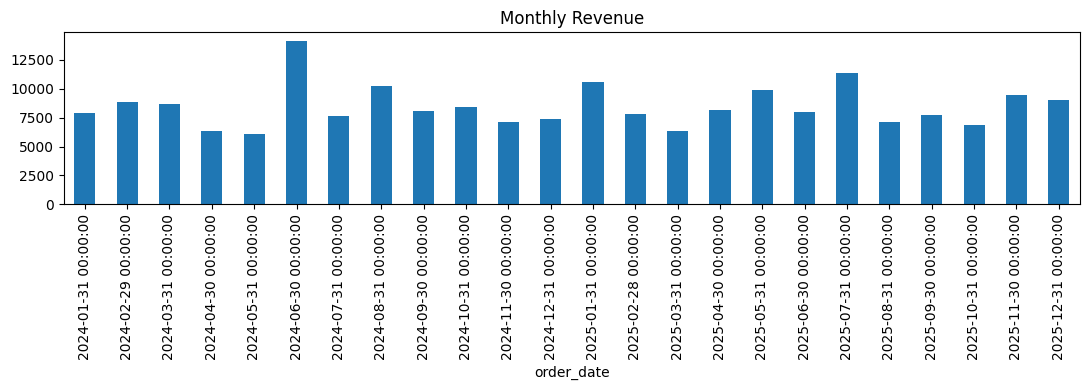

In [7]:
monthly.plot(kind="bar", figsize=(11, 4), title="Monthly Revenue")
plt.tight_layout()
plt.savefig("../output/monthly_revenue.png")
plt.show()

## 3. Rolling windows
A rolling (moving) average smooths out daily noise.

In [8]:
rolling = pd.DataFrame({
    "daily": daily,
    "rolling_7d": daily.rolling(window=7).mean(),
    "rolling_30d": daily.rolling(window=30).mean(),
})
rolling.iloc[28:35]

,daily,rolling_7d,rolling_30d
order_date,,,
2024-01-29,60,421.428571,NaN
2024-01-30,830,505.714286,260.500000
2024-01-31,120,451.428571,262.333333
2024-02-01,240,335.714286,269.000000
2024-02-02,60,201.428571,264.000000
2024-02-03,90,210.714286,264.333333
2024-02-04,50,207.142857,265.500000


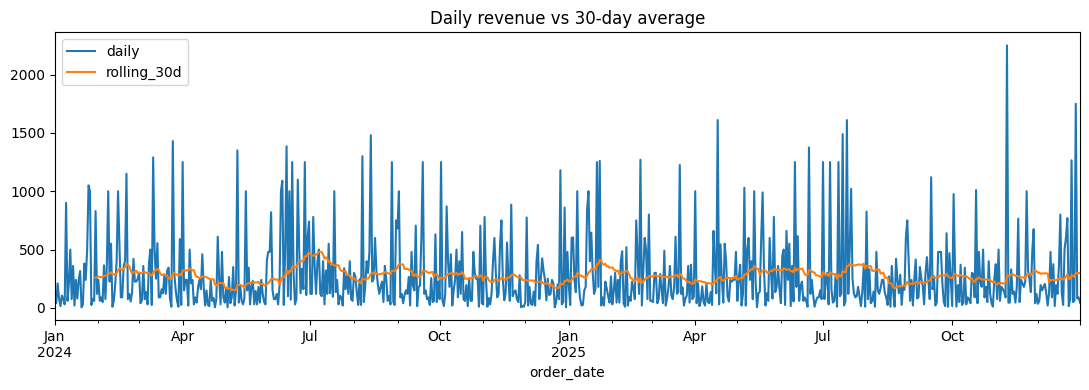

In [9]:
rolling[["daily", "rolling_30d"]].plot(figsize=(11, 4), title="Daily revenue vs 30-day average")
plt.tight_layout()
plt.savefig("../output/rolling_average.png")
plt.show()

In [10]:
# Expanding window = running total / running average
cumulative = daily.expanding().sum()
cumulative.tail(3)

order_date
2025-12-29    202990.0
2025-12-30    203080.0
2025-12-31    203125.0
Freq: D, Name: revenue, dtype: float64

## 4. Shift and lag
`shift(1)` moves values down by one row, which gives the previous period.

In [11]:
m = monthly.to_frame("revenue")
m["previous_month"] = m["revenue"].shift(1)                 # lag
m["change"] = m["revenue"] - m["previous_month"]
m["growth_%"] = (m["revenue"].pct_change() * 100).round(1)  # same idea, built in
m["same_month_last_year"] = m["revenue"].shift(12)
m.head(14)

,revenue,previous_month,change,growth_%,same_month_last_year
order_date,,,,,
2024-01-31,7935,NaN,NaN,NaN,NaN
2024-02-29,8820,7935.0,885.0,11.2,NaN
2024-03-31,8695,8820.0,-125.0,-1.4,NaN
2024-04-30,6370,8695.0,-2325.0,-26.7,NaN
2024-05-31,6110,6370.0,-260.0,-4.1,NaN
2024-06-30,14150,6110.0,8040.0,131.6,NaN
2024-07-31,7675,14150.0,-6475.0,-45.8,NaN
2024-08-31,10235,7675.0,2560.0,33.4,NaN
2024-09-30,8085,10235.0,-2150.0,-21.0,NaN


## 5. Date ranges

In [12]:
print(pd.date_range("2025-01-01", periods=5, freq="D"))
print(pd.date_range("2025-01-01", "2025-06-30", freq="ME"))   # month ends
print(pd.date_range("2025-01-01", periods=5, freq="B"))       # business days only

DatetimeIndex(['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04',
               '2025-01-05'],
              dtype='datetime64[us]', freq='D')
DatetimeIndex(['2025-01-31', '2025-02-28', '2025-03-31', '2025-04-30',
               '2025-05-31', '2025-06-30'],
              dtype='datetime64[us]', freq='ME')
DatetimeIndex(['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-06',
               '2025-01-07'],
              dtype='datetime64[us]', freq='B')


## 6. Time zones
Dates are 'naive' (no time zone) by default. Use `tz_localize` to attach one, `tz_convert` to change it.

In [13]:
times = pd.date_range("2025-01-01 09:00", periods=3, freq="h")
ist = times.tz_localize("Asia/Kolkata")        # India time
print(ist)
print(ist.tz_convert("UTC"))                   # to UTC
print(ist.tz_convert("America/New_York"))      # to New York

DatetimeIndex(['2025-01-01 09:00:00+05:30', '2025-01-01 10:00:00+05:30',
               '2025-01-01 11:00:00+05:30'],
              dtype='datetime64[us, Asia/Kolkata]', freq=None)
DatetimeIndex(['2025-01-01 03:30:00+00:00', '2025-01-01 04:30:00+00:00',
               '2025-01-01 05:30:00+00:00'],
              dtype='datetime64[us, UTC]', freq=None)
DatetimeIndex(['2024-12-31 22:30:00-05:00', '2024-12-31 23:30:00-05:00',
               '2025-01-01 00:30:00-05:00'],
              dtype='datetime64[us, America/New_York]', freq=None)


## 7. Quick insights

In [14]:
best = monthly.idxmax()
print("Best month:", best.strftime("%B %Y"), "->", monthly.max())

by_weekday = daily.groupby(daily.index.day_name()).mean().round(0)
print("\nAverage revenue by weekday:\n", by_weekday)

Best month: June 2024 -> 14150

Average revenue by weekday:
 order_date
Friday       279.0
Monday       283.0
Saturday     269.0
Sunday       253.0
Thursday     293.0
Tuesday      326.0
Wednesday    242.0
Name: revenue, dtype: float64
